# CloudSentinel AI ? Data Exploration

## Run guidance

Restart the kernel, then run every code cell in order. This notebook loads the existing raw CSV itself; it does not require the data-generation notebook to have been run in the same kernel.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

cwd = Path.cwd()
PROJECT_ROOT = next(
    (path for path in (cwd, *cwd.parents)
     if (path / "notebooks").is_dir() and (path / "data").is_dir()),
    cwd,
)
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
print(f"Project root: {PROJECT_ROOT}")

Project root: c:\Users\Abhishek\Desktop\CloudSentinel-AI


In [2]:
RAW_DATA_FILE = RAW_DATA_DIR / "cloud_resource_metrics.csv"
if not RAW_DATA_FILE.exists():
    raise FileNotFoundError(
        f"Dataset not found: {RAW_DATA_FILE}. Run 01_data_generation.ipynb first."
    )

cloud_df = pd.read_csv(RAW_DATA_FILE, parse_dates=["timestamp"])
required_columns = {
    "timestamp", "resource_id", "resource_type", "cpu_utilization",
    "memory_utilization", "network_in", "request_count", "storage_usage",
    "estimated_cost", "is_anomaly", "anomaly_type",
}
missing_columns = required_columns.difference(cloud_df.columns)
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_columns)}")

duplicate_count = int(cloud_df.duplicated().sum())
cloud_df = cloud_df.drop_duplicates().reset_index(drop=True)
print(f"Loaded {len(cloud_df):,} rows from {RAW_DATA_FILE}")
print(f"Duplicate rows removed: {duplicate_count}")
print(f"Missing values remaining: {int(cloud_df.isna().sum().sum())}")
print(f"Timestamp range: {cloud_df['timestamp'].min()} to {cloud_df['timestamp'].max()}")

Loaded 14,400 rows from c:\Users\Abhishek\Desktop\CloudSentinel-AI\data\raw\cloud_resource_metrics.csv
Duplicate rows removed: 0
Missing values remaining: 0
Timestamp range: 2026-08-01 00:00:00 to 2026-08-30 23:45:00


## Dataset overview

We analyze the loaded cloud-resource dataset to understand
normal operating behavior, anomaly patterns, feature distributions,
and relationships between resource utilization and estimated cost.

In [3]:
cloud_df.shape

(14400, 11)

In [4]:
cloud_df.columns.tolist()

['timestamp',
 'resource_id',
 'resource_type',
 'cpu_utilization',
 'memory_utilization',
 'network_in',
 'request_count',
 'storage_usage',
 'estimated_cost',
 'is_anomaly',
 'anomaly_type']

In [5]:
cloud_df.dtypes

timestamp             datetime64[ns]
resource_id                   object
resource_type                 object
cpu_utilization              float64
memory_utilization           float64
network_in                   float64
request_count                float64
storage_usage                float64
estimated_cost               float64
is_anomaly                     int64
anomaly_type                  object
dtype: object

In [6]:
print(cloud_df["timestamp"].dtype)

datetime64[ns]


## 18. Resource Distribution

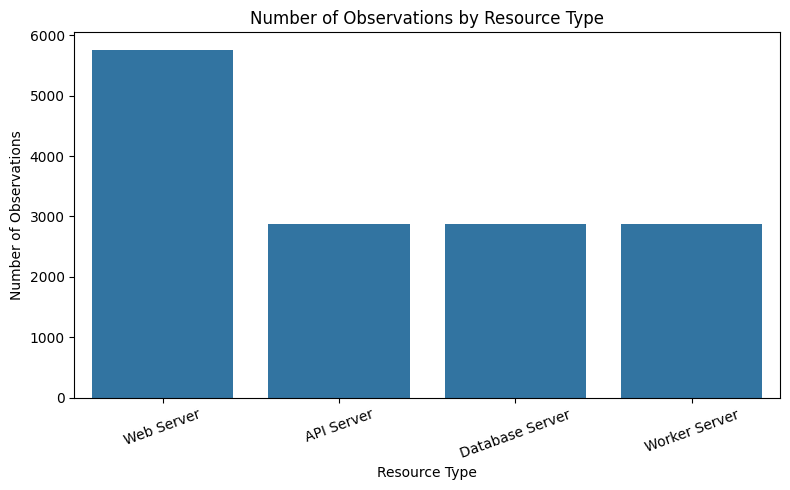

In [7]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=cloud_df,
    x="resource_type"
)

plt.title("Number of Observations by Resource Type")
plt.xlabel("Resource Type")
plt.ylabel("Number of Observations")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 19. Anomaly Distribution

In [8]:
anomaly_counts = cloud_df["anomaly_type"].value_counts()

anomaly_counts

anomaly_type
normal            14300
cpu_spike            25
network_spike        20
memory_spike         20
cost_spike           20
combined_spike       15
Name: count, dtype: int64

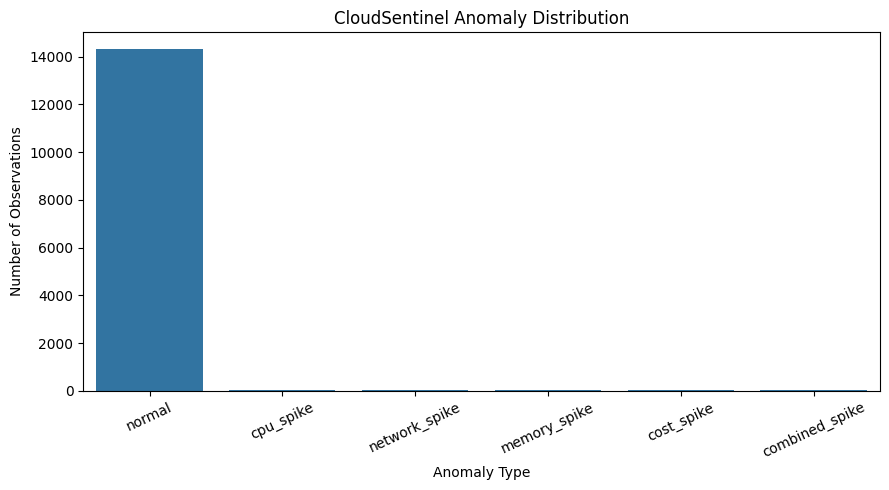

In [9]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=anomaly_counts.index,
    y=anomaly_counts.values
)

plt.title("CloudSentinel Anomaly Distribution")
plt.xlabel("Anomaly Type")
plt.ylabel("Number of Observations")

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

## 20. CPU Utilization Analysis

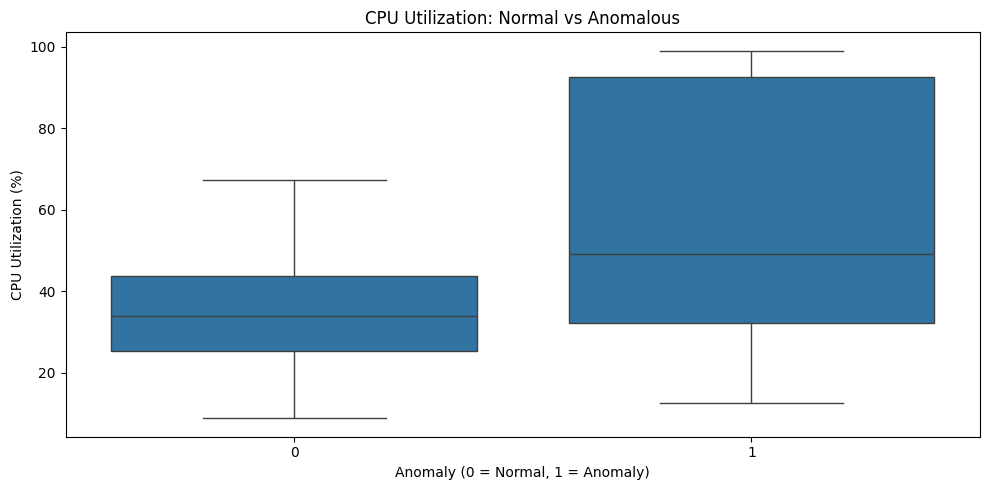

In [10]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=cloud_df,
    x="is_anomaly",
    y="cpu_utilization"
)

plt.title("CPU Utilization: Normal vs Anomalous")
plt.xlabel("Anomaly (0 = Normal, 1 = Anomaly)")
plt.ylabel("CPU Utilization (%)")

plt.tight_layout()
plt.show()

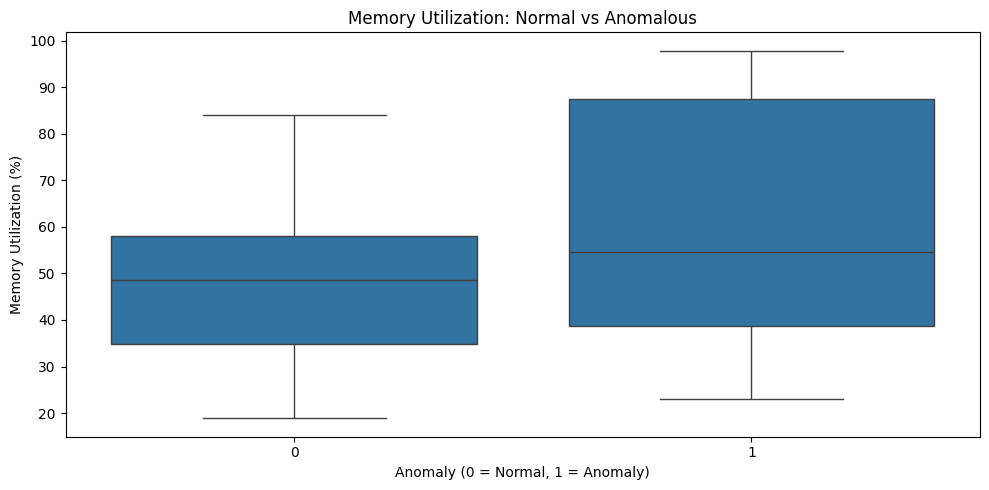

In [11]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=cloud_df,
    x="is_anomaly",
    y="memory_utilization"
)

plt.title("Memory Utilization: Normal vs Anomalous")
plt.xlabel("Anomaly (0 = Normal, 1 = Anomaly)")
plt.ylabel("Memory Utilization (%)")

plt.tight_layout()
plt.show()

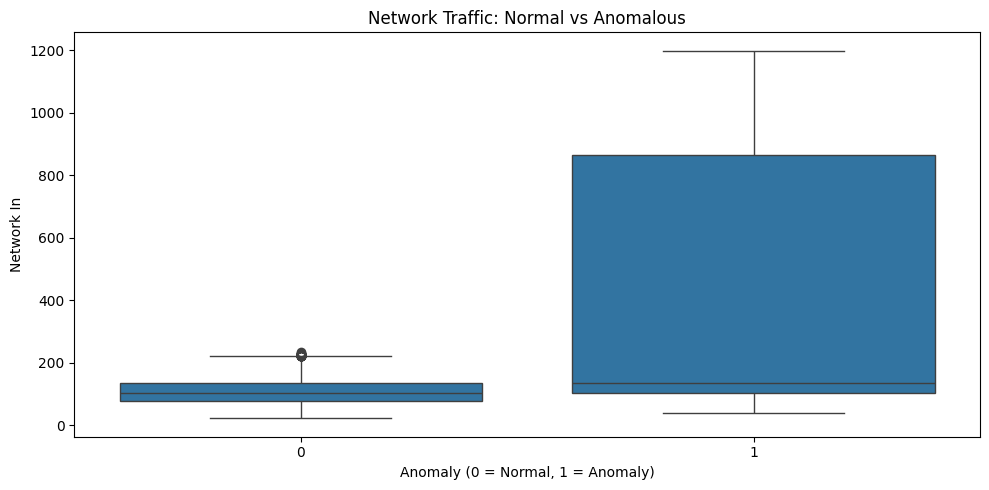

In [12]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=cloud_df,
    x="is_anomaly",
    y="network_in"
)

plt.title("Network Traffic: Normal vs Anomalous")
plt.xlabel("Anomaly (0 = Normal, 1 = Anomaly)")
plt.ylabel("Network In")

plt.tight_layout()
plt.show()

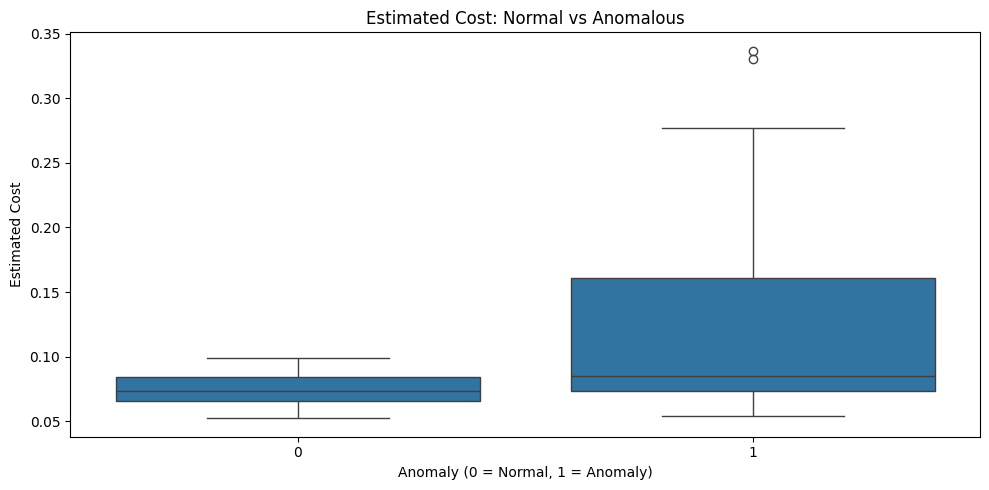

In [13]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=cloud_df,
    x="is_anomaly",
    y="estimated_cost"
)

plt.title("Estimated Cost: Normal vs Anomalous")
plt.xlabel("Anomaly (0 = Normal, 1 = Anomaly)")
plt.ylabel("Estimated Cost")

plt.tight_layout()
plt.show()

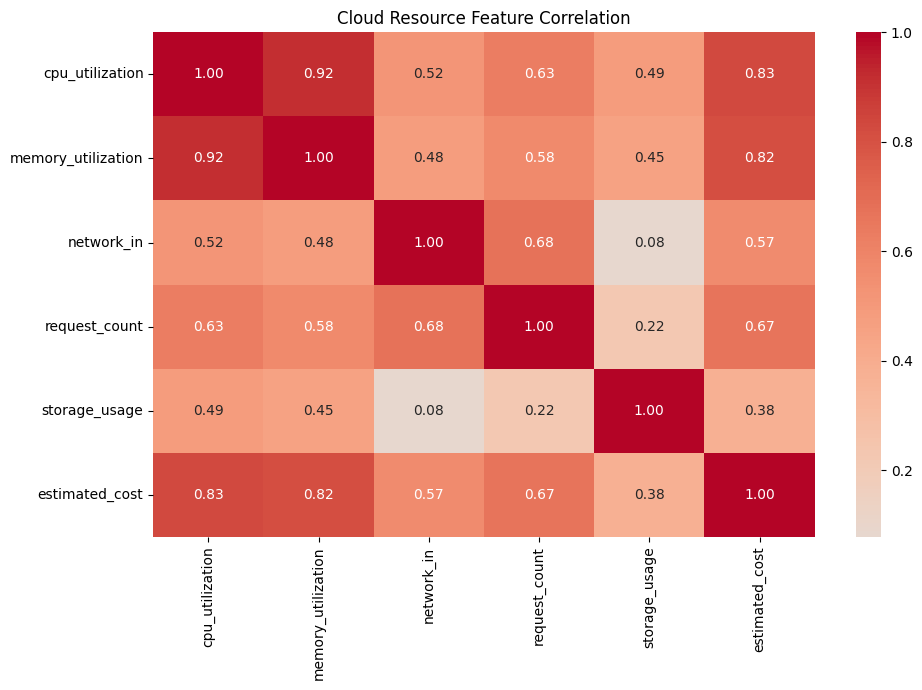

In [14]:
numeric_features = cloud_df.select_dtypes(include="number").drop(
    columns=["is_anomaly"], errors="ignore"
)
correlation_matrix = numeric_features.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Cloud Resource Feature Correlation")
plt.tight_layout()
plt.show()

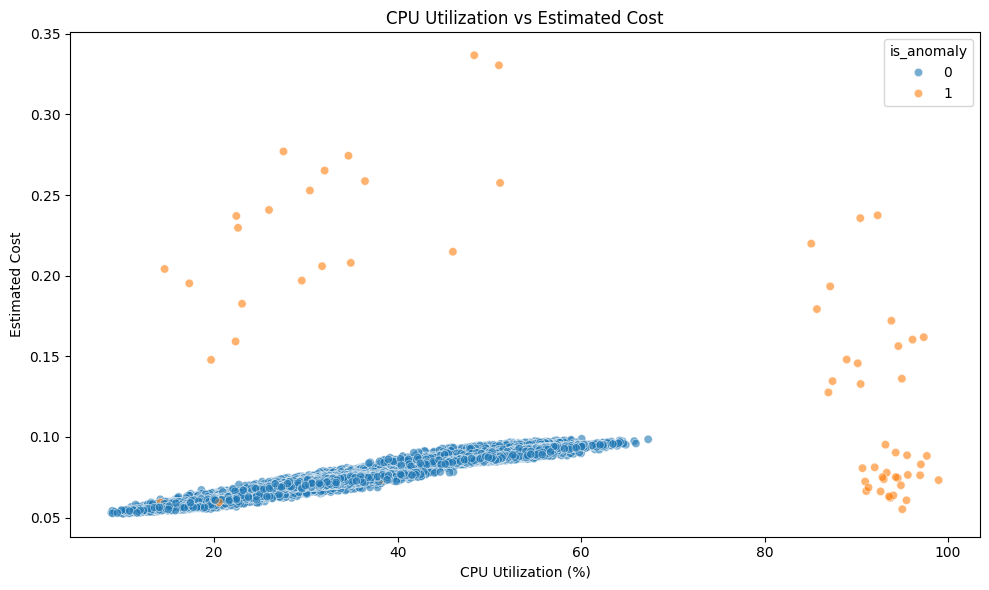

In [15]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=cloud_df,
    x="cpu_utilization",
    y="estimated_cost",
    hue="is_anomaly",
    alpha=0.6
)

plt.title("CPU Utilization vs Estimated Cost")
plt.xlabel("CPU Utilization (%)")
plt.ylabel("Estimated Cost")

plt.tight_layout()
plt.show()

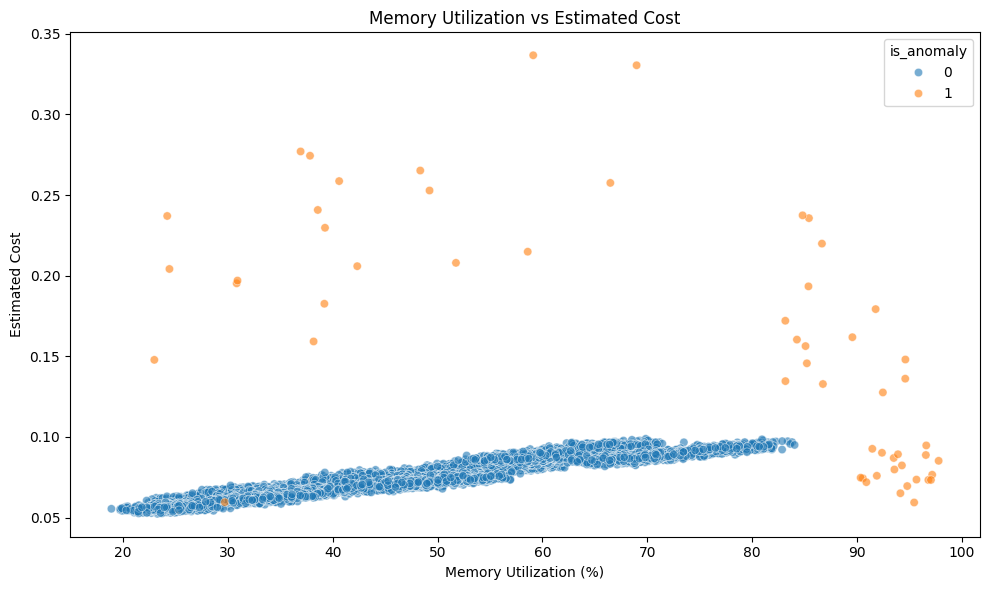

In [16]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=cloud_df,
    x="memory_utilization",
    y="estimated_cost",
    hue="is_anomaly",
    alpha=0.6
)

plt.title("Memory Utilization vs Estimated Cost")
plt.xlabel("Memory Utilization (%)")
plt.ylabel("Estimated Cost")

plt.tight_layout()
plt.show()

In [17]:
resource_summary = cloud_df.groupby(
    "resource_type"
)[
    [
        "cpu_utilization",
        "memory_utilization",
        "network_in",
        "request_count",
        "estimated_cost"
    ]
].mean()

resource_summary

,cpu_utilization,memory_utilization,network_in,request_count,estimated_cost
resource_type,,,,,
API Server,39.398799,50.515824,156.765304,2180.437086,0.081581
Database Server,43.716616,59.350968,89.479877,1048.471377,0.080499
Web Server,32.765669,44.522585,115.953574,1438.422151,0.073573
Worker Server,26.417547,39.348752,81.156272,694.781156,0.066093


## 24. Time-Series Analysis

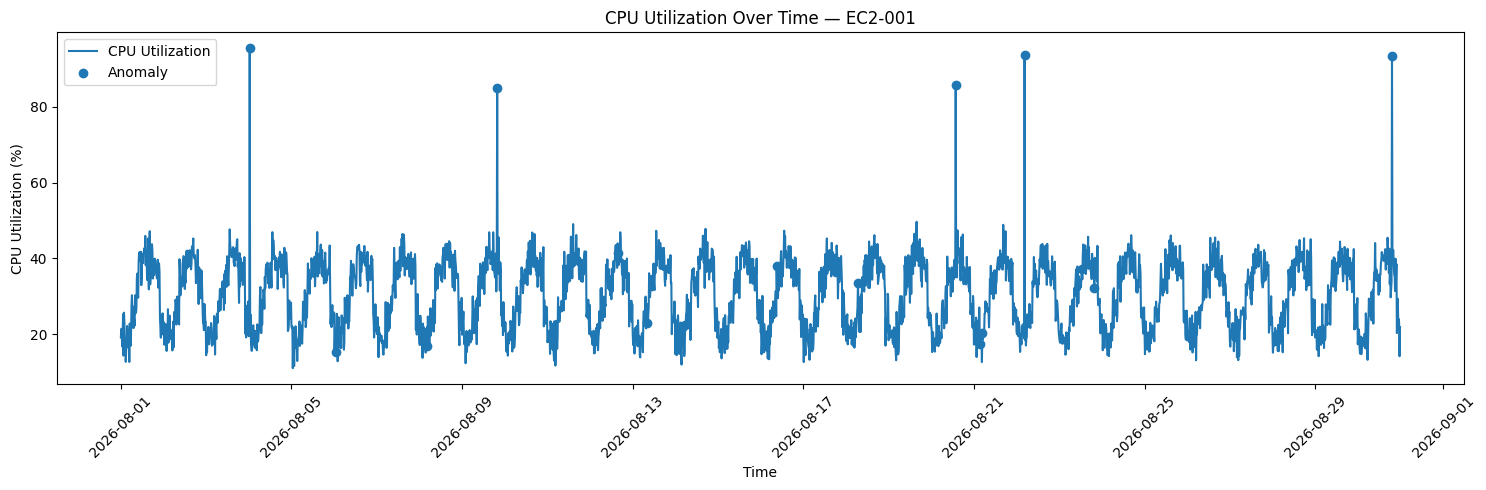

In [18]:
resource_to_plot = "EC2-001"

resource_df = cloud_df[
    cloud_df["resource_id"] == resource_to_plot
].copy()

plt.figure(figsize=(15, 5))

plt.plot(
    resource_df["timestamp"],
    resource_df["cpu_utilization"],
    label="CPU Utilization"
)

anomalies = resource_df[
    resource_df["is_anomaly"] == 1
]

plt.scatter(
    anomalies["timestamp"],
    anomalies["cpu_utilization"],
    label="Anomaly"
)

plt.title(f"CPU Utilization Over Time — {resource_to_plot}")
plt.xlabel("Time")
plt.ylabel("CPU Utilization (%)")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 25. Inspect Known Anomalies

In [19]:
cloud_df[
    cloud_df["is_anomaly"] == 1
].sort_values(
    "timestamp"
).head(20)

,timestamp,resource_id,resource_type,cpu_utilization,memory_utilization,network_in,request_count,storage_usage,estimated_cost,is_anomaly,anomaly_type
2919,2026-08-01 09:45:00,EC2-002,Web Server,41.976483,51.377394,1033.914433,1985.593591,56.745813,0.081529,1,network_spike
5813,2026-08-01 13:15:00,EC2-003,API Server,51.173379,66.486095,213.264546,2783.707125,61.493423,0.257568,1,cost_spike
11582,2026-08-01 15:30:00,EC2-005,Worker Server,95.610496,52.809576,104.250743,898.573960,47.211255,0.076457,1,cpu_spike
5854,2026-08-01 23:30:00,EC2-003,API Server,36.446687,40.610000,131.900468,1782.025465,61.826814,0.258683,1,cost_spike
3025,2026-08-02 12:15:00,EC2-002,Web Server,92.002224,53.818847,138.827036,1849.879187,57.487269,0.081163,1,cpu_spike
11672,2026-08-02 14:00:00,EC2-005,Worker Server,96.953405,54.344267,86.623381,941.142365,46.402088,0.076240,1,cpu_spike
5915,2026-08-02 14:45:00,EC2-003,API Server,51.049029,68.992259,199.357541,2719.366265,59.883172,0.330521,1,cost_spike
8815,2026-08-02 19:45:00,EC2-004,Database Server,52.216230,70.140732,1027.103994,1373.056203,73.378734,0.088557,1,network_spike
8865,2026-08-03 08:15:00,EC2-004,Database Server,30.442669,49.233999,83.332191,975.469513,71.274859,0.252854,1,cost_spike
5989,2026-08-03 09:15:00,EC2-003,API Server,39.518691,97.811569,177.967382,2503.187610,61.821174,0.085212,1,memory_spike


In [20]:
cloud_df[
    cloud_df["is_anomaly"] == 1
]["anomaly_type"].value_counts()

anomaly_type
cpu_spike         25
network_spike     20
memory_spike      20
cost_spike        20
combined_spike    15
Name: count, dtype: int64